In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report#, accuracy_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.model_selection import KFold
from sklearn import linear_model

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv")

In [3]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.shape

(5000, 9)

In [12]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [3]:
df[df.columns[df.dtypes == 'object']] = df[df.columns[df.dtypes == 'object']].fillna('NA')
numeric_cols = df.select_dtypes(include=['number']).columns
df[numeric_cols] = df[numeric_cols].fillna(0)

In [4]:
# Dataset splitting
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

I have to compute the AUC score for every numerical variable, taking it as the prediction score, and the "converted" variable as the actual value. This tells us how correlated these variables are with the target variable. For variables that don't lie on the [0,1] interval, I linearly transform them by mapping $X_{nor} = (X - X_{min})/(X_{max} - X_{min})$.

In [39]:
for var in df.select_dtypes(include=['number']).columns[:-1]:
    #nor_var = (df_train[var] - df_train[var].min()) / (df_train[var].max() - df_train[var].min())
    #scr_nor = roc_auc_score(df_train.converted, nor_var)
    scr = roc_auc_score(df_train.converted, df_train[var])
    print(f"For {var}: {scr}")#, Normalized: {scr_nor}")

For annual_income: 0.6081977776250831
For number_of_courses_viewed: 0.7229894623989618
For interaction_count: 0.7649203047563227
For lead_score: 0.7882254810906102


<span style="color: orange">Q1. Which numerical variable (among the following 4) has the highest AUC?</span>

<span style="color: lightgreen">Ans.: "lead_score" is the variable with the highest AUC score with the target variable.</span>

Now, train a logistic regression model.

In [ ]:
# One-hot encoding
dv = DictVectorizer(sparse=False)

train_dict = df_train.drop(['converted'], axis=1).to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.drop(['converted'], axis=1).to_dict(orient='records')
X_val = dv.transform(val_dict)

test_dict = df_test.drop(['converted'], axis=1).to_dict(orient='records')
X_test = dv.transform(test_dict)

In [ ]:
model = linear_model.LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, df_train.converted)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [19]:
y_pred = model.predict_proba(X_val)[:,1]
roc_auc_score(df_val.converted, y_pred)

0.7318222288173319

<span style="color: orange">Q2. What's the AUC of this model on the validation dataset?</span>

<span style="color: lightgreen">Ans.: 0.732.</span>

In [20]:
scores = []
for t in np.arange(0., 1.001, 0.01):
    # The true positives
    TrPos = ((df_val["converted"] == 1) & (y_pred > t)).sum()

    # The true negatives
    TrNeg = ((df_val["converted"] == 0) & (y_pred < t)).sum()

    # The false positives
    FlPos = ((df_val["converted"] == 0) & (y_pred > t)).sum()

    # The false negatives
    FlNeg = ((df_val["converted"] == 1) & (y_pred < t)).sum()

    scores.append((t, TrPos, TrNeg, FlPos, FlNeg))

scores = pd.DataFrame(scores, columns = ['threshold', 'tp', 'tn', 'fp', 'fn'])

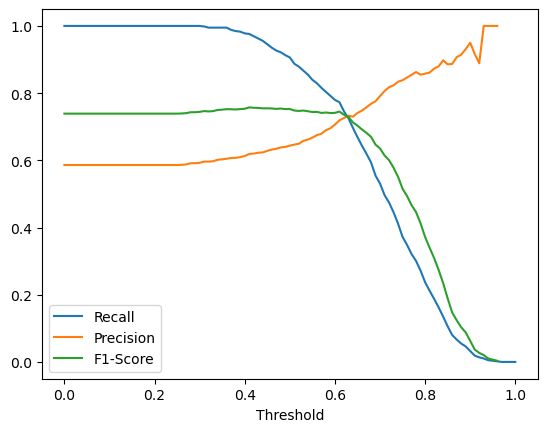

In [21]:
Rec = scores["tp"]/(scores["tp"] + scores["fn"])
Pre = scores["tp"]/(scores["tp"] + scores["fp"])
F1sc = 2*Rec*Pre/(Rec + Pre)

plt.plot(scores["threshold"], Rec, label="Recall")
plt.plot(scores["threshold"], Pre, label="Precision")
plt.plot(scores["threshold"], F1sc, label="F1-Score")
plt.xlabel("Threshold")
plt.legend()
plt.show()

In [22]:
np.argmin(np.abs(Pre - Rec))

np.int64(63)

<span style="color: orange">Q3. At which threshold precision and recall curves intersect?</span>

<span style="color: lightgreen">Ans.: 0.63.</span>

In [23]:
np.argmax(F1sc)

np.int64(41)

<span style="color: orange">Q4. At which threshold F1 is maximal?</span>

<span style="color: lightgreen">Ans.: 0.41.</span>

Now, perform KFold cross validation.

In [24]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1) 

In [25]:
scores = []
 
for train_idx, val_idx in kfold.split(df_full_train):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    train_dict = df_train.drop(['converted'], axis=1).to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)
    
    val_dict = df_val.drop(['converted'], axis=1).to_dict(orient='records')
    X_val = dv.transform(val_dict)
    
    y_train = df_train.converted
    y_val = df_val.converted
 
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:, 1]
 
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

avrsc, stdsc = np.mean(scores), np.std(scores)
print(f"Mean AUC: {avrsc:.3f}, std: {stdsc:.3f}")

Mean AUC: 0.732, std: 0.007


<span style="color: orange">Q5. How large is standard deviation of the scores across different folds?</span>

<span style="color: lightgreen">Ans.: 0.007.</span>

In [26]:
scores = []
for c in [0.000001, 0.001, 1]:
    model = linear_model.LogisticRegression(solver='liblinear', C=c, max_iter=1000)

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        train_dict = df_train.drop(['converted'], axis=1).to_dict(orient='records')
        X_train = dv.fit_transform(train_dict)
        
        val_dict = df_val.drop(['converted'], axis=1).to_dict(orient='records')
        X_val = dv.transform(val_dict)
        
        y_train = df_train.converted
        y_val = df_val.converted
    
        model.fit(X_train, y_train)
        y_pred = model.predict_proba(X_val)[:, 1]
    
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    avrsc, stdsc = np.mean(scores), np.std(scores)
    print(f"C: {model.C}, Mean AUC: {avrsc:.3f}, std: {stdsc:.3f}")

C: 1e-06, Mean AUC: 0.617, std: 0.019
C: 0.001, Mean AUC: 0.683, std: 0.068
C: 1, Mean AUC: 0.699, std: 0.060


<span style="color: orange">Q6. Which C leads to the best mean ROC AUC?</span>

<span style="color: lightgreen">Ans.: C=0.001 and C=1 give the best mean ROC AUC score, and they show no difference within one standard deviation around the mean. So I pick the parameter with the smallest standard deviation, which is C=1.</span>